# Taller 6: Generación de texto y traducción automática con modelos secuenciales

**Curso:** Procesamiento de Lenguaje Natural

**Universidad:** Pontificia Universidad Javeriana

**Integrantes:** Cristian Organista, Fabian Ramirez, Cristhian Bolaños

**Repositorio:** https://github.com/crissebasbol/nlp-course

## Objetivo

Aplicar redes neuronales recurrentes (RNN) sobre texto en español en dos tareas clásicas del PLN:

1. **Modelado del lenguaje:** entrenar un modelo que aprenda el estilo de un libro y genere texto nuevo carácter por carácter.
2. **Traducción automática:** entrenar un modelo codificador-decodificador que traduzca frases del **español al inglés** y evaluarlo con métricas estándar.

## Punto 1: Modelo de generación de texto

- Un libro en español (Don Quijote)
- **Preprocesamiento:** limpieza del encabezado y pie de licencia de Gutenberg, división en secuencias de longitud fija y tokenización a nivel de **carácter**.
- **Modelo:** `Embedding` + `GRU` + `Dense(softmax)`. En cada posición, el modelo predice el siguiente carácter a partir de los anteriores.
- **Generación:** se copia el peso del modelo entrenado a un modelo con estado (*stateful*) que genera texto a partir de un *prompt*, comparando decodificación voraz (*greedy*) y muestreo con temperatura.

## Punto 2: Traducción español → inglés (seq2seq)

- **Dataset:** *Combined Data es-ES* (~98 000 frases). Cada registro tiene el texto original en inglés (`statement`) y su traducción al español (`statement_es_es`).
- **Modelo:** arquitectura codificador-decodificador con RNN. El codificador es una `GRU` bidireccional que lee la frase en español y el decodificador es una `GRU` que genera la frase en inglés token por token (*teacher forcing* durante el entrenamiento).
- **Evaluación** sobre el conjunto de prueba:
  - **BLEU:** precisión de n-gramas entre la traducción generada y la de referencia.
  - **ROUGE (1, 2, L):** cobertura (*recall*) de n-gramas y de la subsecuencia común más larga.
  - **F1-score:** media armónica entre precisión y *recall* a nivel de tokens.

# Punto 1: modelo de generación de texto a partir de un libro

## Instalación y configuración del backend

In [43]:
!pip install keras keras-hub keras-nlp --upgrade -q

In [44]:
import os
os.environ["KERAS_BACKEND"] = "jax"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import jax
import keras

print("Keras version:", keras.__version__)
print("JAX backend:", jax.default_backend())
print("Devices:", jax.devices())

Keras version: 3.13.2
JAX backend: gpu
Devices: [CudaDevice(id=0)]


JAX detectó una GPU CUDA (CudaDevice(id=0), la T4 de Colab).

Al desactivar XLA_PYTHON_CLIENT_PREALLOCATE, JAX no reserva toda la memoria de la GPU de entrada.


In [9]:
# Imports

import re
import tensorflow as tf
from keras import layers
import time
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## Descarga y limpieza del libro seleccionado

Se selecciona Don Quijote

In [4]:
ruta_archivo = keras.utils.get_file(
    fname="don_quijote.txt",
    origin="https://www.gutenberg.org/cache/epub/2000/pg2000.txt",
)
with open(ruta_archivo, "r", encoding="utf-8") as f:
    texto_crudo = f.read()

2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [5]:
texto_crudo[:1000]

'The Project Gutenberg eBook of Don Quijote\n    \nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restrictions\nwhatsoever. You may copy it, give it away or re-use it under the terms\nof the Project Gutenberg License included with this eBook or online\nat www.gutenberg.org. If you are not located in the United States,\nyou will have to check the laws of the country where you are located\nbefore using this eBook.\n\nTitle: Don Quijote\n\nAuthor: Miguel de Cervantes Saavedra\n\n\n        \nRelease date: December 1, 1999 [eBook #2000]\n                Most recently updated: January 17, 2021\n\nLanguage: Spanish\n\nOther information and formats: www.gutenberg.org/ebooks/2000\n\nCredits: an anonymous Project Gutenberg volunteer and Joaquin Cuenca Abela\n\n\n*** START OF THE PROJECT GUTENBERG EBOOK DON QUIJOTE ***\n\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n\npor Miguel de Cervantes Saavedra\n

In [6]:
texto_crudo[-18700:-18000]

's no ha sido otro mi deseo que\nponer en aborrecimiento de los hombres las fingidas y disparatadas\nhistorias de los libros de caballerías, que, por las de mi verdadero don\nQuijote, van ya tropezando, y han de caer del todo, sin duda alguna. Vale.\n\nFin\n\n\n\n\n\n\n*** END OF THE PROJECT GUTENBERG EBOOK DON QUIJOTE ***\n\n\n    \n\nUpdated editions will replace the previous one—the old editions will\nbe renamed.\n\nCreating the works from print editions not protected by U.S. copyright\nlaw means that no one owns a United States copyright in these works,\nso the Foundation (and you!) can copy and distribute it in the United\nStates without permission and without paying copyright\nroyalties. Special rules, set for'

Normalizar los saltos de línea

In [7]:
texto_crudo = texto_crudo.replace("\r\n", "\n").lstrip("")

Conservar solo el cuerpo del libro, entre los marcadores START y END de Gutenberg

In [8]:
inicio = texto_crudo.index("*** START OF THE PROJECT GUTENBERG EBOOK")
inicio = texto_crudo.index("\n", inicio) + 1
fin = texto_crudo.index("*** END OF THE PROJECT GUTENBERG EBOOK")
libro = texto_crudo[inicio:fin]

In [9]:
libro[:1000]

'\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n\npor Miguel de Cervantes Saavedra\n\n\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n  \nTasa\n\n  \nTestimonio de las erratas\n\n  \nEl Rey\n\n  \nAl Duque de Béjar\n\n  \nPrólogo\n\n  \nAl libro de don Quijote de la Mancha\n\n\n\nQue trata de la condición y ejercicio del famoso\nhidalgo don Quijote de la Mancha\n\nQue trata de la primera salida que de su tierra hizo\nel ingenioso don Quijote\n\nDonde se cuenta la graciosa manera que tuvo don\nQuijote en armarse caballero\n\nDe lo que le sucedió a nuestro caballero cuando salió\nde la venta\n\nDonde se prosigue la narración de la desgracia de\nnuestro caballero\n\nDel donoso y grande escrutinio que el cura y el\nbarbero hicieron en la librería de nuestro ingenioso hidalgo\n\nDe la segunda salida de nuestro buen caballero don\nQuijote de la Mancha\n\nDel buen suceso que el valeroso don Quijote tuvo en\nla espantable y jamás imaginada aventura de los molinos de vien

Quitar espacios al final de cada línea

In [10]:
libro = "\n".join(linea.rstrip() for linea in libro.split("\n"))

In [11]:
libro[:1000]

'\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n\npor Miguel de Cervantes Saavedra\n\n\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n\nTasa\n\n\nTestimonio de las erratas\n\n\nEl Rey\n\n\nAl Duque de Béjar\n\n\nPrólogo\n\n\nAl libro de don Quijote de la Mancha\n\n\n\nQue trata de la condición y ejercicio del famoso\nhidalgo don Quijote de la Mancha\n\nQue trata de la primera salida que de su tierra hizo\nel ingenioso don Quijote\n\nDonde se cuenta la graciosa manera que tuvo don\nQuijote en armarse caballero\n\nDe lo que le sucedió a nuestro caballero cuando salió\nde la venta\n\nDonde se prosigue la narración de la desgracia de\nnuestro caballero\n\nDel donoso y grande escrutinio que el cura y el\nbarbero hicieron en la librería de nuestro ingenioso hidalgo\n\nDe la segunda salida de nuestro buen caballero don\nQuijote de la Mancha\n\nDel buen suceso que el valeroso don Quijote tuvo en\nla espantable y jamás imaginada aventura de los molinos de viento, con\notr

In [12]:
libro = re.sub(r"\n{3,}", "\n\n", libro).strip()

In [13]:
libro[:1000]

'El ingenioso hidalgo don Quijote de la Mancha\n\npor Miguel de Cervantes Saavedra\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\nTasa\n\nTestimonio de las erratas\n\nEl Rey\n\nAl Duque de Béjar\n\nPrólogo\n\nAl libro de don Quijote de la Mancha\n\nQue trata de la condición y ejercicio del famoso\nhidalgo don Quijote de la Mancha\n\nQue trata de la primera salida que de su tierra hizo\nel ingenioso don Quijote\n\nDonde se cuenta la graciosa manera que tuvo don\nQuijote en armarse caballero\n\nDe lo que le sucedió a nuestro caballero cuando salió\nde la venta\n\nDonde se prosigue la narración de la desgracia de\nnuestro caballero\n\nDel donoso y grande escrutinio que el cura y el\nbarbero hicieron en la librería de nuestro ingenioso hidalgo\n\nDe la segunda salida de nuestro buen caballero don\nQuijote de la Mancha\n\nDel buen suceso que el valeroso don Quijote tuvo en\nla espantable y jamás imaginada aventura de los molinos de viento, con\notros sucesos dignos de felice recordació

In [14]:
print("Caracteres del texto crudo:", len(texto_crudo))
print("Caracteres del texto limpio:", len(libro))
print("Caracteres únicos:", len(set(libro)))
print("Vocabulario:", "".join(sorted(set(libro))))
print("-" * 60)
print(libro[2000:2200])

Caracteres del texto crudo: 2130057
Caracteres del texto limpio: 2110296
Caracteres únicos: 92
Vocabulario: 
 !"'(),-.01234567:;?ABCDEFGHIJLMNOPQRSTUVWXYZ]abcdefghijlmnopqrstuvxyz¡«»¿ÁÉÍÑÓÚàáéíïñóùúü—
------------------------------------------------------------
ue le sucedió con un cuerpo muerto, con otros
acontecimientos famosos

De la jamás vista ni oída aventura que con más poco
peligro fue acabada de famoso caballero en el mundo, como la que acabó
el val


- La limpieza eliminó 19k caracteres (menos del 1 %): la licencia de Gutenberg, los `\r` de Windows y los espacios y líneas vacías sobrantes. Quedan **~2.11 millones de caracteres** de texto real de Cervantes, casi el doble que el corpus de Shakespeare del ejemplo (~1.1 millones).
- El vocabulario tiene **92 caracteres únicos**. Vocales con tilde (minúsculas y mayúsculas), `ñ`/`Ñ`, `ü`, los signos de apertura `¿` y `¡`, las comillas latinas `« »` y la raya de diálogo `—`. El modelo tendrá que aprender, por ejemplo, que `¿` abre una pregunta que se cierra con `?`.

## secuencias de entrenamiento y validación

El texto se parte en secuencias de 100 caracteres. La entrada es cada secuencia y la etiqueta es la misma secuencia desplazada un carácter a la derecha, de modo que en cada posición el modelo aprende a predecir el siguiente carácter. Se reserva el último 10 % de las secuencias como validación, para detectar sobreajuste durante el entrenamiento.

In [15]:
longitud_secuencia = 100

In [16]:
def dividir_texto(texto, longitud):
    for i in range(0, len(texto), longitud):
        yield texto[i : i + longitud]

La etiqueta es la entrada desplazada un carácter: predecir el siguiente carácter

In [17]:
entradas = list(dividir_texto(libro[:-1], longitud_secuencia))

In [18]:
entradas[:3]

['El ingenioso hidalgo don Quijote de la Mancha\n\npor Miguel de Cervantes Saavedra\n\nEl ingenioso hidalg',
 'o don Quijote de la Mancha\n\nTasa\n\nTestimonio de las erratas\n\nEl Rey\n\nAl Duque de Béjar\n\nPrólogo\n\nAl ',
 'libro de don Quijote de la Mancha\n\nQue trata de la condición y ejercicio del famoso\nhidalgo don Quij']

In [19]:
etiquetas = list(dividir_texto(libro[1:], longitud_secuencia))

In [20]:
etiquetas[:3]

['l ingenioso hidalgo don Quijote de la Mancha\n\npor Miguel de Cervantes Saavedra\n\nEl ingenioso hidalgo',
 ' don Quijote de la Mancha\n\nTasa\n\nTestimonio de las erratas\n\nEl Rey\n\nAl Duque de Béjar\n\nPrólogo\n\nAl l',
 'ibro de don Quijote de la Mancha\n\nQue trata de la condición y ejercicio del famoso\nhidalgo don Quijo']

Reservar el último 10 % de las secuencias para validación

In [21]:
len(entradas)

21103

In [22]:
n_validacion = int(0.1 * len(entradas))

In [23]:
n_validacion

2110

In [24]:
n_entrenamiento = len(entradas) - n_validacion

In [25]:
n_entrenamiento

18993

In [26]:
dataset_entrenamiento = tf.data.Dataset.from_tensor_slices(
    (entradas[:n_entrenamiento], etiquetas[:n_entrenamiento])
)

In [27]:
dataset_validacion = tf.data.Dataset.from_tensor_slices(
    (entradas[n_entrenamiento:], etiquetas[n_entrenamiento:])
)

In [28]:
print("Secuencias totales:", len(entradas))
print("Secuencias de entrenamiento:", n_entrenamiento)
print("Secuencias de validación:", n_validacion)

Secuencias totales: 21103
Secuencias de entrenamiento: 18993
Secuencias de validación: 2110


In [29]:
x, y = next(dataset_entrenamiento.as_numpy_iterator())

In [30]:
print("Entrada: ", repr(x[:].decode("utf-8", errors="ignore")))
print("Etiqueta:", repr(y[:].decode("utf-8", errors="ignore")))

Entrada:  'El ingenioso hidalgo don Quijote de la Mancha\n\npor Miguel de Cervantes Saavedra\n\nEl ingenioso hidalg'
Etiqueta: 'l ingenioso hidalgo don Quijote de la Mancha\n\npor Miguel de Cervantes Saavedra\n\nEl ingenioso hidalgo'


- El libro se dividió en **21 103 secuencias** de 100 caracteres: **18 993 para entrenamiento** (90 %) y **2 110 para validación** (10 %). La validación corresponde al tramo final de la Segunda Parte del Quijote, un texto que el modelo nunca verá durante el entrenamiento.
- El ejemplo confirma que la etiqueta es la entrada **desplazada un carácter**: la entrada empieza en `El ingenioso...` y la etiqueta en `l ingenioso...`, y la etiqueta termina con la `o` de `hidalgo` que le falta a la entrada. En cada una de las 100 posiciones el modelo debe predecir el carácter siguiente, así que cada secuencia aporta 100 ejemplos de entrenamiento.

## Tokenización por caracteres y preparación de los lotes

Se crea un TextVectorization que separa por carácter y se ajusta solo con el texto de entrenamiento. Después se convierten ambos datasets a IDs enteros y se agrupan en lotes de 64.

In [51]:
tamano_lote = 64

In [33]:
tokenizador = layers.TextVectorization(
    standardize=None,
    split="character",
    output_sequence_length=longitud_secuencia,
)

Ajustar el vocabulario solo con las entradas de entrenamiento

In [34]:
tokenizador.adapt(dataset_entrenamiento.map(lambda entrada, etiqueta: entrada))

In [35]:
tamano_vocabulario = tokenizador.vocabulary_size()

In [36]:
print("Tamaño del vocabulario:", tamano_vocabulario)
print("Primeros tokens:", tokenizador.get_vocabulary()[:20])

Tamaño del vocabulario: 93
Primeros tokens: ['', '[UNK]', np.str_(' '), np.str_('e'), np.str_('a'), np.str_('o'), np.str_('s'), np.str_('n'), np.str_('r'), np.str_('l'), np.str_('d'), np.str_('u'), np.str_('i'), np.str_('t'), np.str_('c'), np.str_('m'), np.str_(','), np.str_('\n'), np.str_('p'), np.str_('q')]


In [37]:
def tokenizar(entrada, etiqueta):
    return tokenizador(entrada), tokenizador(etiqueta)

In [39]:
datos_entrenamiento = (
    dataset_entrenamiento
    .map(tokenizar, num_parallel_calls=tf.data.AUTOTUNE)
    .cache() # Evita tener que volver a procesar y tokenizar el texto en cada iteración de entrenamiento
    .shuffle(10_000) # Mezcla aleatoriamente los datos utilizando un búfer
    .batch(tamano_lote)
    .prefetch(tf.data.AUTOTUNE) # Permite que la CPU prepare los siguientes lotes de datos en segundo plano
)

In [40]:
datos_validacion = (
    dataset_validacion
    .map(tokenizar, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(tamano_lote)
    .cache()
)

In [41]:
x_lote, y_lote = next(iter(datos_entrenamiento))

In [42]:
print("Forma de las entradas del lote:", x_lote.shape)
print("Forma de las etiquetas del lote:", y_lote.shape)
print("Primeros IDs de la entrada:", x_lote[0, :20].numpy())

Forma de las entradas del lote: (64, 100)
Forma de las etiquetas del lote: (64, 100)
Primeros IDs de la entrada: [ 2  4 17  6 11  6  2 14  4 11 13 12 23  5  6 16  2 19 11  3]


- El vocabulario tiene **93 tokens**: 2 especiales (`''` para el relleno o *padding*, con ID 0, y `[UNK]` para caracteres desconocidos, con ID 1) más **91 caracteres**. El libro completo tiene 92 caracteres únicos, así que uno quedó por fuera: la **`ù`**, que solo aparece en el 10 % final reservado para validación. En validación se mapeará a `[UNK]`. Es un ejemplo de por qué el vocabulario se ajusta solo con el conjunto de entrenamiento: así se simula el caso real de encontrar símbolos nunca vistos.
- `TextVectorization` ordena el vocabulario por **frecuencia**.
- Cada lote tiene forma **(64, 100)**: 64 secuencias de 100 caracteres, tanto en las entradas como en las etiquetas.

## Arquitectura del modelo de lenguaje

Se define el modelo:

* Embedding: convierte cada ID de carácter en un vector denso de 256 dimensiones.
* GRU: red recurrente. Entrega una salida por cada posición, de modo que se predice el siguiente carácter en las 100 posiciones a la vez.
* Dropout: apaga el 10 % de las activaciones como regularización.
* Dense con softmax: produce una distribución de probabilidad sobre los 93 tokens del vocabulario.

In [43]:
dim_embedding = 256
dim_oculta = 1024

In [45]:
entradas_modelo = layers.Input(shape=(longitud_secuencia,), dtype="int", name="token_ids")

In [47]:
x = layers.Embedding(tamano_vocabulario, dim_embedding)(entradas_modelo)

In [48]:
x = layers.GRU(dim_oculta, return_sequences=True)(x)

In [49]:
x = layers.Dropout(0.1)(x)

In [50]:
salidas_modelo = layers.Dense(tamano_vocabulario, activation="softmax")(x)

In [51]:
modelo = keras.Model(entradas_modelo, salidas_modelo)

In [53]:
modelo.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 100, 256)       │        23,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 100, 1024)      │     3,938,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 1024)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100, 93)        │        95,325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,437 (15.48 MB)

 Trainable params: 4,057,437 (15.48 MB)

 Non-trainable params: 0 (0.00 B)

- El modelo tiene **~4 millones de parámetros**.
- La **GRU concentra el ~97 % de los parámetros**. La mayor parte de la capacidad del modelo está en la memoria recurrente, que es la que aprende las dependencias entre caracteres: formar palabras, concordancias, puntuación y estructura de los diálogos.
- La forma de salida **(None, 100, 93)** indica que, para cada una de las 100 posiciones de la secuencia, el modelo entrega una distribución de probabilidad sobre los 93 tokens del vocabulario.
- El modelo tiene **~4 millones de parámetros** y el conjunto de entrenamiento **~1.9 millones de caracteres**, es decir, más parámetros que ejemplos. Hay riesgo de memorización, y la pérdida de validación permitirá detectarlo durante el entrenamiento.

## Entrenamiento

Se compila con adam y pérdida, porque las etiquetas son IDs enteros y no vectores one-hot. Se entrena hasta 15 épocas con dos callbacks:

* EarlyStopping: detiene el entrenamiento si la pérdida de validación no mejora en 2 épocas seguidas y restaura los mejores pesos.
* ModelCheckpoint: guarda en disco el mejor modelo, para no perder el entrenamiento si Colab se desconecta.

In [57]:
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)

# sparse_categorical_accuracy: Calcula con qué frecuencia las predicciones del
# modelo coinciden con las etiquetas reales cuando estas etiquetas se proporcionan
# como valores enteros

In [58]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "modelo_quijote.keras", monitor="val_loss", save_best_only=True
    ),
]

In [59]:
inicio_entrenamiento = time.time()
historial = modelo.fit(
    datos_entrenamiento,
    validation_data=datos_validacion,
    epochs=15,
    callbacks=callbacks,
)
minutos = (time.time() - inicio_entrenamiento) / 60

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 34s 99ms/step - loss: 2.3036 - sparse_categorical_accuracy: 0.3392 - val_loss: 1.8377 - val_sparse_categorical_accuracy: 0.4397
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 82ms/step - loss: 1.6676 - sparse_categorical_accuracy: 0.4891 - val_loss: 1.5142 - val_sparse_categorical_accuracy: 0.5369
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - loss: 1.4504 - sparse_categorical_accuracy: 0.5517 - val_loss: 1.3887 - val_sparse_categorical_accuracy: 0.5698
Epoch 4/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 81ms/step - loss: 1.3451 - sparse_categorical_accuracy: 0.5785 - val_loss: 1.3220 - val_sparse_categorical_accuracy: 0.5861
Epoch 5/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - loss: 1.2793 - sparse_categorical_accuracy: 0.5957 - val_loss: 1.2852 - val_sparse_categorical_accuracy: 0.5963
Epoch 6/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 80ms/step - loss: 1.2314 - sparse_categorical_accuracy: 0.6087 - val_loss: 1.2641 - val_sparse_categorical_accuracy:

In [60]:
print(f"Tiempo total de entrenamiento: {minutos:.1f} minutos")

Tiempo total de entrenamiento: 4.2 minutos


- **`EarlyStopping` detuvo el entrenamiento en la época 10** de 15. La mejor pérdida de validación se alcanzó en la **época 8 (val_loss = 1.2443, val_accuracy = 60.9 %)**, y esos son los pesos que quedaron en el modelo gracias a `restore_best_weights=True`.
- **Sobreajuste:** a partir de la época 8, la pérdida de entrenamiento sigue bajando (1.155 → 1.088) mientras que la de validación sube (1.244 → 1.253). El modelo empieza a memorizar el texto de entrenamiento en lugar de generalizar. Era lo esperable, porque tiene más parámetros (~4M) que caracteres de entrenamiento (~1.9M).
- En las épocas 9 y 10, la *accuracy* de validación sube levemente mientras la pérdida empeora. El modelo acierta un poco más, pero se vuelve **demasiado confiado en sus errores**, y la entropía cruzada castiga fuertemente las predicciones erróneas con alta probabilidad. Por eso `val_loss` es mejor criterio de parada que `val_accuracy`.
- Una precisión del **~61 %** en el siguiente carácter es razonable para un modelo a nivel de carácter. Muchas posiciones son genuinamente ambiguas (el inicio de una palabra nueva, por ejemplo), mientras que los finales de palabra suelen ser casi deterministas.

## Curvas de aprendizaje

In [62]:
metricas = pd.DataFrame(historial.history)
metricas.index = range(1, len(metricas) + 1)
metricas.index.name = "época"
print(metricas.round(4).to_string())

         loss  sparse_categorical_accuracy  val_loss  val_sparse_categorical_accuracy
época                                                                                
1      2.3036                       0.3392    1.8377                           0.4397
2      1.6676                       0.4891    1.5142                           0.5369
3      1.4504                       0.5517    1.3887                           0.5698
4      1.3451                       0.5785    1.3220                           0.5861
5      1.2793                       0.5957    1.2852                           0.5963
6      1.2314                       0.6087    1.2641                           0.6034
7      1.1912                       0.6192    1.2491                           0.6070
8      1.1552                       0.6293    1.2443                           0.6092
9      1.1211                       0.6389    1.2472                           0.6099
10     1.0883                       0.6487    1.2529  

In [63]:
mejor_epoca = int(metricas["val_loss"].idxmin())
print(f"Mejor época (menor val_loss): {mejor_epoca}")
print(f"Épocas ejecutadas: {len(metricas)}")

Mejor época (menor val_loss): 8
Épocas ejecutadas: 10


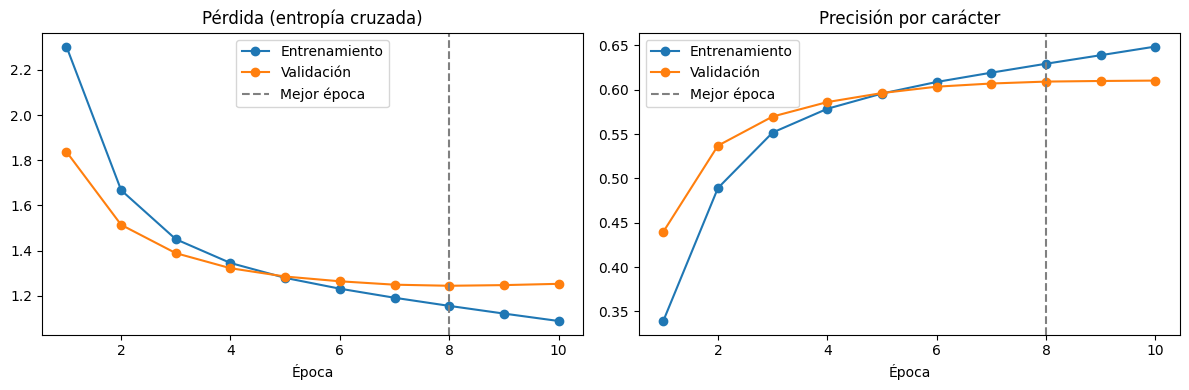

In [64]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(metricas.index, metricas["loss"], marker="o", label="Entrenamiento")
ejes[0].plot(metricas.index, metricas["val_loss"], marker="o", label="Validación")
ejes[0].axvline(mejor_epoca, color="gray", linestyle="--", label="Mejor época")
ejes[0].set_title("Pérdida (entropía cruzada)")
ejes[0].set_xlabel("Época")
ejes[0].legend()

ejes[1].plot(metricas.index, metricas["sparse_categorical_accuracy"], marker="o", label="Entrenamiento")
ejes[1].plot(metricas.index, metricas["val_sparse_categorical_accuracy"], marker="o", label="Validación")
ejes[1].axvline(mejor_epoca, color="gray", linestyle="--", label="Mejor época")
ejes[1].set_title("Precisión por carácter")
ejes[1].set_xlabel("Época")
ejes[1].legend()

plt.tight_layout()
plt.show()

- Las curvas muestran tres fases claras:
  1. **Épocas 1 a 4, aprendizaje rápido:** ambas pérdidas caen fuertemente (de 2.30 a 1.35 en entrenamiento). El modelo aprende primero lo más frecuente: espacios, vocales y palabras cortas como "de", "la", "que".
  2. **Época 5, cruce de las curvas:** las curvas de entrenamiento y validación se cruzan, tanto en pérdida (~1.28) como en precisión (~59.6 %). Antes del cruce, la validación es mejor por efecto del *dropout*. Después, el entrenamiento pasa a ser mejor.
  3. **Épocas 6 a 10, divergencia:** la curva de entrenamiento sigue mejorando de forma casi lineal, pero la de validación se aplana y, desde la época 8, la pérdida empieza a subir. La brecha creciente entre ambas curvas es la señal visual del **sobreajuste**.
- La **época 8** (línea punteada) es el punto óptimo de generalización y es la que se conserva. Entrenar más solo haría que el modelo memorizara el Quijote en lugar de aprender a escribir como Cervantes.

## Modelo de generación y función para generar texto

El modelo entrenado procesa secuencias completas de 100 caracteres. Para generar, conviene un modelo que reciba un carácter a la vez y devuelva también su estado oculto, para pasarlo al siguiente paso.

Se genera con las siguientes dos faseS:
* Lectura del prompt: pasa el texto inicial carácter por carácter para "calentar" el estado oculto.
* Generación: en cada paso elige el siguiente carácter.


In [67]:
entrada_caracter = keras.Input(shape=(1,), dtype="int", name="token_ids")
entrada_estado = keras.Input(shape=(dim_oculta,), name="estado")

In [68]:
x = layers.Embedding(tamano_vocabulario, dim_embedding)(entrada_caracter)
x, estado_salida = layers.GRU(dim_oculta, return_state=True)(
    x, initial_state=entrada_estado
)
salida_caracter = layers.Dense(tamano_vocabulario, activation="softmax")(x)

In [69]:
modelo_generacion = keras.Model(
    inputs=(entrada_caracter, entrada_estado),
    outputs=(salida_caracter, estado_salida),
)

Copiar los pesos del mejor modelo entrenado (época 8)

In [70]:
modelo_generacion.set_weights(modelo.get_weights())

In [71]:
vocabulario = tokenizador.get_vocabulary()
caracter_a_id = {caracter: i for i, caracter in enumerate(vocabulario)}
id_a_caracter = {i: caracter for i, caracter in enumerate(vocabulario)}

In [76]:
def paso(id_caracter, estado):
    entrada = keras.ops.convert_to_tensor([[id_caracter]], dtype="int32")
    probabilidades, estado = modelo_generacion((entrada, estado), training=False)
    return keras.ops.convert_to_numpy(probabilidades)[0], estado

def elegir_siguiente(probabilidades, temperatura):
    probabilidades = probabilidades.copy()
    probabilidades[:2] = 0  # excluir padding y [UNK]
    if temperatura == 0:
        return int(np.argmax(probabilidades))
    logits = np.log(probabilidades + 1e-9) / temperatura
    probabilidades = np.exp(logits - logits.max())
    probabilidades /= probabilidades.sum()
    return int(np.random.choice(len(probabilidades), p=probabilidades))

def generar_texto(prompt, longitud=300, temperatura=0.0):
    estado = keras.ops.zeros((1, dim_oculta))
    for caracter in prompt:
        probabilidades, estado = paso(caracter_a_id.get(caracter, 1), estado)
    generados = []
    for _ in range(longitud):
        siguiente = elegir_siguiente(probabilidades, temperatura)
        generados.append(id_a_caracter[siguiente])
        probabilidades, estado = paso(siguiente, estado)
    return prompt + "".join(generados)

In [77]:
print(generar_texto("En un lugar de la Mancha", longitud=300, temperatura=0))

En un lugar de la Mancha, y en la cual después de haber salido a la cabeza de la caballería que en el camino del
caballo de la Mancha, porque en la cabeza de la caballería que en el mundo se había de parar a su señora, y en la cual después de haber
de ser alguna cosa de su parte, que es mucho que de todo este tiempo que es


- **El modelo no memorizó el libro:** la frase original continúa "...de cuyo nombre no quiero acordarme", pero el modelo generó una continuación propia. Esto concuerda con haber detenido el entrenamiento en la época 8, antes de que el sobreajuste fuera fuerte.
- **Aprendió la forma del español a nivel de carácter:** todas las palabras generadas existen, las tildes están bien puestas (*después*, *había*, *caballería*) y usa comas y saltos de línea.
- **Aprendió el estilo y el vocabulario del Quijote:** aparecen *caballería*, *señora*, *la Mancha*, *camino* y *caballo*, y construcciones de prosa del Siglo de Oro como "que en el mundo se había de", "alguna cosa de su parte".
- **Hay coherencia local, pero no global:** las frases son gramaticalmente plausibles en tramos cortos, pero el texto no tiene un hilo de sentido.

# Efecto de la temperatura en la generación

Se genera texto con el mismo prompt y distintas temperaturas, para comparar:

* Temperatura baja (0.2 a 0.5): se concentra en los caracteres más probables. Da un texto seguro, pero tiende a repetirse.
* Temperatura media (0.7 a 0.8): suele dar el mejor equilibrio entre coherencia y variedad.
* Temperatura alta (1.0 a 1.2): aplana la distribución. Da un texto más creativo, pero con palabras inventadas y errores ortográficos.

In [81]:
np.random.seed(42)
prompt = "Dijo don Quijote a Sancho"

In [82]:
for temperatura in [0.2, 0.5, 0.8, 1.0, 1.2]:
    print(f"Temperatura {temperatura}")
    print(generar_texto(prompt, longitud=300, temperatura=temperatura))
    print()

Temperatura 0.2
Dijo don Quijote a Sancho Panza y en la cabeza de la cabeza, y con el mundo que le despude otro
desta manera: que está a la cabeza de su parte que está a la cueva de Montesinos, que está a la cabeza de la caballería que en el camino en la cabeza de
la caballería que le había de dar a entender que está a la cueva de Montesin

Temperatura 0.5
Dijo don Quijote a Sancho Panza, y no hay más que para lo que pasaba de su cuerpo del mundo; y es que
era un hombre, cuando tengo que está a la mora en mi amo se ha de cubierta, y no es mi honra
si tienen por más que de la historia, y para esto como de aquéllas no ha
de ser alguna nueva en el mundo.

Y, en esto, en esto, se

Temperatura 0.8
Dijo don Quijote a Sancho que no treía bien con las pensamientos en su
compañía, tan cirta de las comodidades, y con la mano para ver desta voz que con mucho triste del rucio, y a buen
seguro que para el mundo que venía prometido que el rucio este caballero andante pecado; y de
la cueva de Montesi

La temperatura controla el equilibrio entre **coherencia** y **diversidad**. Los resultados muestran una progresión clara:

| Temperatura | Repeticiones | Palabras inventadas | Calidad general |
|---|---|---|---|
| 0.2 | Muchas ("a la cabeza de" ×4, "cueva de Montesinos" ×2) | Casi ninguna (*despude*) | Correcto pero monótono, casi igual al modo voraz |
| 0.5 | Pocas ("en esto, en esto") | Ninguna | Frases fluidas y bien puntuadas |
| 0.8 | Ninguna | Pocas (*treía*, *cirta*) | **Mejor equilibrio**: vocabulario rico y estilo muy cervantino |
| 1.0 | Ninguna | Varias (*escadas*, *prendezaba*, *agomodado*) | Creativo, pero pierde la ortografía |
| 1.2 | Ninguna | Muchas (*peodes*, *santingada*, *Zamilaldos*) | Casi un "pseudo-español" |



## Experimento con variantes

Se comparan dos variantes contra el modelo base (GRU de 1024, dropout 0.1), entrenadas con los mismos datos y los mismos callbacks:

* GRU 1024, dropout 0.3
* 2 GRU apiladas de 512, dropout 0.1



In [83]:
def construir_modelo(capas_gru, dropout):
    entradas = layers.Input(shape=(longitud_secuencia,), dtype="int", name="token_ids")
    x = layers.Embedding(tamano_vocabulario, dim_embedding)(entradas)
    for unidades in capas_gru:
        x = layers.GRU(unidades, return_sequences=True)(x)
        x = layers.Dropout(dropout)(x)
    salidas = layers.Dense(tamano_vocabulario, activation="softmax")(x)
    return keras.Model(entradas, salidas)

In [84]:
def resumir(nombre, hist, parametros, minutos_entrenamiento):
    mejor = int(np.argmin(hist["val_loss"]))
    return {
        "variante": nombre,
        "parámetros": parametros,
        "épocas": len(hist["val_loss"]),
        "mejor época": mejor + 1,
        "val_loss": round(hist["val_loss"][mejor], 4),
        "val_accuracy": round(hist["val_sparse_categorical_accuracy"][mejor], 4),
        "perplejidad": round(float(np.exp(hist["val_loss"][mejor])), 3),
        "brecha (val - train)": round(hist["val_loss"][mejor] - hist["loss"][mejor], 4),
        "minutos": round(minutos_entrenamiento, 1),
    }

In [85]:
nombre_base = "Base: GRU 1024, dropout 0.1"
historiales = {nombre_base: historial.history}
modelos_experimento = {nombre_base: modelo}
resumen = [resumir(nombre_base, historial.history, modelo.count_params(), minutos)]

In [86]:
experimentos = {
    "GRU 1024, dropout 0.3": ([1024], 0.3),
    "2 GRU 512, dropout 0.1": ([512, 512], 0.1),
}

In [87]:
for nombre, (capas_gru, dropout) in experimentos.items():
    print(f"\n===== {nombre} =====")
    modelo_exp = construir_modelo(capas_gru, dropout)
    modelo_exp.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"],
    )
    inicio_exp = time.time()
    hist_exp = modelo_exp.fit(
        datos_entrenamiento,
        validation_data=datos_validacion,
        epochs=20,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=2, restore_best_weights=True
            )
        ],
        verbose=2,
    )
    minutos_exp = (time.time() - inicio_exp) / 60
    historiales[nombre] = hist_exp.history
    modelos_experimento[nombre] = modelo_exp
    resumen.append(resumir(nombre, hist_exp.history, modelo_exp.count_params(), minutos_exp))

tabla_resumen = pd.DataFrame(resumen).set_index("variante")
print()
print(tabla_resumen.to_string())


===== GRU 1024, dropout 0.3 =====
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


297/297 - 26s - 89ms/step - loss: 2.3003 - sparse_categorical_accuracy: 0.3372 - val_loss: 1.8417 - val_sparse_categorical_accuracy: 0.4359
Epoch 2/20
297/297 - 20s - 68ms/step - loss: 1.7014 - sparse_categorical_accuracy: 0.4789 - val_loss: 1.5383 - val_sparse_categorical_accuracy: 0.5272
Epoch 3/20
297/297 - 21s - 69ms/step - loss: 1.4937 - sparse_categorical_accuracy: 0.5388 - val_loss: 1.4019 - val_sparse_categorical_accuracy: 0.5652
Epoch 4/20
297/297 - 21s - 71ms/step - loss: 1.3876 - sparse_categorical_accuracy: 0.5671 - val_loss: 1.3352 - val_sparse_categorical_accuracy: 0.5841
Epoch 5/20
297/297 - 21s - 72ms/step - loss: 1.3231 - sparse_categorical_accuracy: 0.5841 - val_loss: 1.2973 - val_sparse_categorical_accuracy: 0.5935
Epoch 6/20
297/297 - 22s - 75ms/step - loss: 1.2758 - sparse_categorical_accuracy: 0.5972 - val_loss: 1.2721 - val_sparse_categorical_accuracy: 0.6005
Epoch 7/20
297/297 - 22s - 75ms/step - loss: 1.2373 - sparse_categorical_accuracy: 0.6079 - val_loss: 1.2

| Variante | Parámetros | Mejor época | val_loss | Perplejidad | Brecha val - train | ms/paso |
|---|---|---|---|---|---|---|
| Base: GRU 1024, dropout 0.1 | 4.06 M | 8 | 1.2443 | 3.470 | 0.089 | ~80 |
| GRU 1024, dropout 0.3 | 4.06 M | 9 | 1.2420 | 3.462 | **0.068** | ~75 |
| **2 GRU 512, dropout 0.1** | **2.83 M** | 14 | **1.2351** | **3.439** | 0.127 | **~62** |

- **Dropout 0.3:** La brecha entre validación y entrenamiento bajó de 0.089 a **0.068** (−24 %), y la mejor época se desplazó de la 8 a la 9: el sobreajuste se redujo y llegó más tarde. Sin embargo, la `val_loss` apenas mejoró (1.2443 → 1.2420). Más regularización frena la memorización, pero no hace que el modelo aprenda patrones nuevos.
- **2 GRU apiladas de 512: la mejor variante.** Obtuvo la menor `val_loss` (**1.2351**) y la mayor precisión (**61.3 %**) con **30 % menos parámetros**. Además, cada paso es ~22 % más rápido (62 ms frente a 80 ms), porque las matrices recurrentes de dos capas de 512 (2 × 512² ≈ 0.5M pesos) son la mitad de grandes que las de una capa de 1024 (1024² ≈ 1M pesos). Esto respalda la idea de que **la profundidad aporta más que el ancho**: la primera capa puede especializarse en patrones de letras y sílabas, y la segunda en patrones de palabras.
- **Las diferencias son pequeñas:** entre la mejor y la peor variante hay solo 0.009 de `val_loss` (~0.7 %), y la perplejidad pasa de 3.47 a 3.44. Con una sola ejecución por variante, parte de esa diferencia puede deberse a la aleatoriedad de la inicialización y del orden de los lotes. Para afirmarlo con rigor habría que repetir cada configuración con varias semillas.
- **Las tres variantes convergen a una meseta de ~1.24.** Esto sugiere que el límite actual no está en la arquitectura sino en los **datos**: ~1.9 millones de caracteres de un solo libro. Las mejoras más prometedoras serían ampliar el corpus (por ejemplo, con las *Novelas ejemplares* de Cervantes) o dar más contexto al modelo (secuencias más largas o un Transformer), más que seguir ajustando hiperparámetros de la GRU.

## Comparación

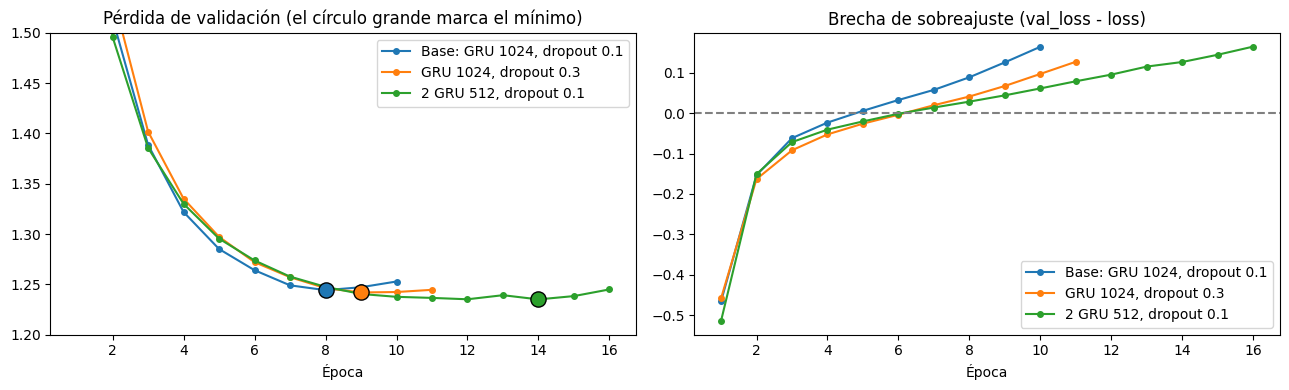

In [88]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

for nombre, hist in historiales.items():
    epocas = range(1, len(hist["val_loss"]) + 1)
    linea, = ejes[0].plot(epocas, hist["val_loss"], marker="o", markersize=4, label=nombre)
    mejor = int(np.argmin(hist["val_loss"]))
    ejes[0].scatter(mejor + 1, hist["val_loss"][mejor], s=120, color=linea.get_color(), edgecolor="black", zorder=3)
    ejes[1].plot(epocas, np.array(hist["val_loss"]) - np.array(hist["loss"]), marker="o", markersize=4, label=nombre)

ejes[0].set_title("Pérdida de validación (el círculo grande marca el mínimo)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylim(1.2, 1.5)
ejes[0].legend()

ejes[1].axhline(0, color="gray", linestyle="--")
ejes[1].set_title("Brecha de sobreajuste (val_loss - loss)")
ejes[1].set_xlabel("Época")
ejes[1].legend()

plt.tight_layout()
plt.show()

**Conclusiones:**

- **Pérdida de validación (izquierda):**
  - Las tres curvas son casi idénticas hasta la época 7. La arquitectura apenas cambia la velocidad de aprendizaje inicial, aunque el modelo base baja un poco más rápido entre las épocas 4 y 8.
  - La diferencia está en **cuánto tiempo sigue mejorando cada modelo**. El base toca fondo en la época 8 y sube enseguida. El de *dropout* 0.3 aguanta una época más. El apilado (verde) se mantiene en una meseta larga y estable entre las épocas 9 y 15, donde alcanza el mínimo global en la 14.
  - Todas las curvas convergen a la franja de **1.235 a 1.245**, lo que confirma que existe un techo común.
- **Brecha de sobreajuste (derecha):**
  - En las primeras épocas la brecha es negativa, porque la validación es mejor que el entrenamiento por efecto del *dropout*. Las curvas cruzan el cero alrededor de la **época 5** en el base y de la **época 6** en las otras dos variantes.
  - Después del cruce, la brecha crece casi linealmente, y **la pendiente indica qué tan rápido memoriza cada modelo**. El base tiene la pendiente más pronunciada. El de *dropout* 0.3 la reduce, como se esperaba. El apilado tiene la **pendiente más suave de todas**: en la época 10, la brecha es de ~0.17 en el base, ~0.10 con *dropout* 0.3 y solo ~0.06 en el apilado.
  
  
- **Conclusión del experimento:** el modelo de **2 GRU apiladas de 512** es la mejor opción en todos los criterios: menor `val_loss`, menor sobreajuste por época, menos parámetros y entrenamiento más rápido por paso. El *dropout* 0.3 ayuda a controlar el sobreajuste, pero reducir y distribuir la capacidad en varias capas resultó más efectivo.

# Punto 2: traducción español → inglés con seq2seq

## Carga y exploración del dataset

In [11]:
datos = pd.read_csv("/content/Combined Data es-ES.csv", index_col=0)

In [12]:
print("Forma:", datos.shape)
print("Columnas:", datos.columns.tolist())
print("Valores faltantes:")
print(datos.isna().sum())

Forma: (53043, 3)
Columnas: ['statement', 'status', 'statement_es_es']
Valores faltantes:
statement          362
status               0
statement_es_es     45
dtype: int64


In [13]:
datos = datos.dropna(subset=["statement", "statement_es_es"])
palabras_es = datos["statement_es_es"].str.split().str.len()
palabras_en = datos["statement"].str.split().str.len()

print("Pares con texto en ambos idiomas:", len(datos))
print("Longitud en palabras:")
print(pd.DataFrame({"español": palabras_es, "inglés": palabras_en}).describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
).round(1).to_string())

Pares con texto en ambos idiomas: 52680
Longitud en palabras:
       español   inglés
count  52680.0  52680.0
mean      89.9    113.2
std      127.4    163.7
min        1.0      1.0
25%       15.0     15.0
50%       53.0     62.0
75%      120.0    148.0
90%      216.0    279.0
max     5087.0   6300.0


In [14]:
print("Pares con ambas frases de hasta N palabras:")
for limite in [10, 15, 20, 25, 30]:
    cantidad = ((palabras_es <= limite) & (palabras_en <= limite)).sum()
    print(f"  <= {limite} palabras: {cantidad}")

print("Categorías (status):")
print(datos["status"].value_counts().to_string())

Pares con ambas frases de hasta N palabras:
  <= 10 palabras: 9226
  <= 15 palabras: 12743
  <= 20 palabras: 15475
  <= 25 palabras: 17724
  <= 30 palabras: 19366
Categorías (status):
status
Normal                  16343
Depression              15404
Suicidal                10651
Anxiety                  3841
Bipolar                  2777
Stress                   2587
Personality disorder     1077


In [15]:
print("Ejemplos aleatorios:")
for _, fila in datos[palabras_en <= 20].sample(8, random_state=1).iterrows():
    print(f"  ES: {fila['statement_es_es']}")
    print(f"  EN: {fila['statement']}\n")

Ejemplos aleatorios:
  ES: ansioso
  EN: anxious

  ES: Parece que ahora es nuevo que 8000 t es ahora 8550 t....
  EN: it seems like it's new now that 8000 t is now 8550 t....

  ES: ¿Quién dice eso?
  EN: who thinks that?

  ES: [BB] Dilligirias de que venden ropa coreana así, chicos. Gracias.
  EN: [BB] Spill towqo that sells Korean clothes like that, guys. Thanksâ

  ES: ¡Oh Allah! Muchas gracias
  EN: Oh Allah! Thanks you a lot

  ES: Kitashin realmente tiene unas muy buenas vibras
  EN: Kitashin really has great vibes

  ES: Acabo de terminar una relación después de dos años, no me siento muy bien. Primera vez que publico
  EN: I just got broken up with after a 2 year relationship not feeling the greatest First time posting

  ES: Sí, con las instrucciones para votar.
  EN: yes, with the voter instructions.



- El dataset tiene **53 043 registros** y 3 columnas: `statement` (texto original en inglés), `status` (categoría de salud mental) y `statement_es_es` (traducción al español). Para este punto solo interesan las dos columnas de texto: el español es la **entrada** y el inglés la **salida**. La columna `status` no se usa.
- Hay **407 valores faltantes** (362 en inglés y 45 en español). Al descartarlos quedan **52 680 pares** utilizables.
- **Las frases son muy largas para un seq2seq con RNN.** La mediana es de 53 palabras en español y 62 en inglés, el 10 % supera las 216/279 palabras y hay textos de más de 5.000. Son publicaciones de redes sociales y foros, no frases cortas de un corpus de traducción. Un codificador RNN comprime toda la frase en **un único vector de estado** (de 1024 dimensiones en este caso), y con textos de cientos de palabras ese vector se convierte en un cuello de botella que pierde información.
- **Se filtrarán los pares de hasta 20 palabras**, lo que deja 15.500 pares. Es un compromiso: con 10 palabras quedarían frases demasiado simples (9.200 pares), y con 30 se ganan solo 4.000 pares a cambio de secuencias más difíciles. Aun así, el corpus resultante es **~8 veces más pequeño** que el del ejemplo del libro (~118 000 pares), así que es esperable un desempeño modesto.
- **Hay ruido que conviene limpiar:**
  - Caracteres corruptos por mala codificación, típicamente emojis convertidos en basura (`Thanksâ`).
  - Nombres propios y jerga de redes (*Kitashin*, *[BB]*).
  - Traducciones imperfectas: "*who thinks that?*" se tradujo como "*¿Quién dice eso?*", y en "*Thanks you a lot*" el error de gramática está en el original.

## Limpieza, filtrado y división del dataset

1. Quitar pares con URLs: no aportan al aprendizaje del idioma.
2. Eliminar caracteres no permitidos: se conservan solo letras (incluidas las del español), dígitos y puntuación básica. Esto elimina los emojis corruptos (ð, Ÿ, â, €...).
3. Filtrar por longitud: de 1 a 20 palabras en ambos idiomas.
4. Quitar pares sin traducir: el texto en español es igual al inglés.
5. Eliminar pares duplicados: así evitamos que la misma frase quede en entrenamiento y en prueba.

In [16]:
# Imports

import random
import re
import string

In [17]:
max_palabras = 20
patron_url = r"http|www\.|\.com"
patron_no_permitidos = r"[^a-zA-Z0-9áéíóúüñÁÉÍÓÚÜÑ¿¡?!.,;:'\s-]"

In [18]:
def limpiar(serie):
    serie = serie.str.replace(patron_no_permitidos, " ", regex=True)
    return serie.str.replace(r"\s+", " ", regex=True).str.strip()

In [19]:
def normalizar(serie):
    return serie.str.lower().str.strip(" .!?¿¡")

In [20]:
pares = datos[["statement_es_es", "statement"]].rename(
    columns={"statement_es_es": "espanol", "statement": "ingles"}
)

In [21]:
embudo = [("Pares sin valores faltantes", len(pares))]
con_url = (
    pares["espanol"].str.contains(patron_url, case=False, regex=True)
    | pares["ingles"].str.contains(patron_url, case=False, regex=True)
)
pares = pares[~con_url].copy()
embudo.append(("Sin URLs", len(pares)))

In [22]:
pares["espanol"] = limpiar(pares["espanol"])
pares["ingles"] = limpiar(pares["ingles"])

In [23]:
palabras_es = pares["espanol"].str.split().str.len()
palabras_en = pares["ingles"].str.split().str.len()
pares = pares[
    palabras_es.between(1, max_palabras) & palabras_en.between(1, max_palabras)
]

In [24]:
embudo.append((f"Entre 1 y {max_palabras} palabras", len(pares)))
pares = pares[normalizar(pares["espanol"]) != normalizar(pares["ingles"])]
embudo.append(("Con traducción real (español != inglés)", len(pares)))

In [25]:
pares = pares.drop_duplicates()
embudo.append(("Sin duplicados", len(pares)))

In [26]:
print("Embudo de limpieza:")
for paso, cantidad in embudo:
    print(f"  {paso:<42} {cantidad:>6}")

Embudo de limpieza:
  Pares sin valores faltantes                 52680
  Sin URLs                                    51538
  Entre 1 y 20 palabras                       15103
  Con traducción real (español != inglés)     14233
  Sin duplicados                              14080


In [27]:
# Pares (español, inglés con tokens de inicio y fin)
pares_texto = [
    (espanol, "[start] " + ingles + " [end]")
    for espanol, ingles in zip(pares["espanol"], pares["ingles"])
]

In [28]:
pares_texto[:3]

[('ay Dios mío', '[start] oh my gosh [end]'),
 ('problemas para dormir, mente confundida, corazón inquieto. Todo desafinada',
  '[start] trouble sleeping, confused mind, restless heart. All out of tune [end]'),
 ('todo mal, aléjate cariño, duda hacia adelante. Quédate en un lugar inquieto y angustiado',
  '[start] All wrong, back off dear, forward doubt. Stay in a restless and restless place [end]')]

In [29]:
random.seed(42)

In [30]:
random.shuffle(pares_texto)

In [31]:
n_val = int(0.15 * len(pares_texto))
n_train = len(pares_texto) - 2 * n_val
pares_entrenamiento = pares_texto[:n_train]
pares_validacion = pares_texto[n_train : n_train + n_val]
pares_prueba = pares_texto[n_train + n_val :]

print(f"Entrenamiento: {len(pares_entrenamiento)}")
print(f"Validación:    {len(pares_validacion)}")
print(f"Prueba:        {len(pares_prueba)}")

Entrenamiento: 9856
Validación:    2112
Prueba:        2112


In [32]:
print("Ejemplos de entrenamiento:")
for espanol, ingles in pares_entrenamiento[:5]:
    print(f"  ES: {espanol}")
    print(f"  EN: {ingles}\n")

Ejemplos de entrenamiento:
  ES: Si la religión es solo de letra muerta, Google es mucho más religioso.
  EN: [start] If religion is only rote, Google is much more religious [end]

  ES: ¿De verdad?
  EN: [start] are you serious? [end]

  ES: Quiero vomitar cuando pienso en mí mismo odio mi vida
  EN: [start] It literally makes me want to vomit when I think about myself I hate myself [end]

  ES: Astagfirullah, mi residencia está hecha un desastre :
  EN: [start] Astagfirullah, my boarding house is a mess : [end]

  ES: Honestamente, eso es todo. Ni siquiera quiero explicarlo. Quiero morir.
  EN: [start] Honestly that is all. I do not even want to explain. I want to die [end]



- **El embudo de limpieza** dejó **14 080 pares** de los 52 680 iniciales (26.7 %):
  - Las URLs eliminaron 1 142 pares (2.2 %).
  - **El filtro de longitud fue el paso más drástico**: descartó el 70 % de los pares, porque la mayoría de los textos son publicaciones largas.
  - 870 pares (5.8 % de los cortos) **no estaban traducidos**: el texto en "español" era idéntico al inglés, típicamente nombres propios, onomatopeyas o frases en otros idiomas.
  - 153 pares estaban **duplicados**. Al quitarlos se evita que la misma frase aparezca en entrenamiento y en prueba, lo que inflaría las métricas.
- **División 70/15/15:** 9 856 pares de entrenamiento, 2 112 de validación y 2 112 de prueba. Validación sirve para monitorear el entrenamiento y prueba se reserva **exclusivamente** para calcular BLEU, ROUGE y F1 al final.
- **Las traducciones del dataset no son literales.** "*¿De verdad?*" corresponde a "*are you serious?*", y "*Quiero vomitar cuando pienso en mí mismo odio mi vida*" omite "*It literally makes me*" del original. El español es una traducción **parafraseada y a veces resumida** del inglés, así que el modelo tendrá que "reconstruir" información que no está en la entrada. Esto pone un techo a las métricas basadas en coincidencia exacta de palabras, como BLEU.
- **El dominio es sensible:** muchas frases expresan angustia o ideación suicida ("*Quiero morir*"), por el origen del dataset (publicaciones clasificadas por estado de salud mental). El vocabulario emocional será frecuente, y el modelo probablemente traducirá bien expresiones como "*I want to die*" o "*I hate myself*", que se repiten mucho.
- Los tokens `[start]` y `[end]` quedaron bien ubicados en el inglés. Servirán como señal de inicio para el decodificador y como condición de parada durante la generación.

## Tokenización por palabras y preparación de los lotes

A diferencia del Punto 1, aquí se tokeniza por palabras. Ambos tokenizadores usan la misma estandarización: minúsculas y eliminación de la puntuación, incluidos ¿ y ¡, pero conservando los corchetes para que [start] y [end] sobrevivan como tokens.

Hiperparámetros:

* Vocabulario de 8 000 palabras por idioma. En el conjunto de entrenamiento hay ~13 000 palabras únicas en español y ~11 600 en inglés, pero ~64 % aparecen una sola vez. Esas palabras raras no se pueden aprender bien con un solo ejemplo, así que se agrupan en [UNK]. Con 8 000 palabras se cubre ~94 % del texto en español y ~97 % en inglés.
* Longitudes: 20 tokens para el español (el máximo tras el filtro) y 22 para el inglés (20 palabras + [start] + [end]). El tokenizador del inglés produce 23 tokens para poder desplazar la secuencia un paso, igual que en el Punto 1.

In [33]:
tamano_vocab = 8000
longitud_origen = max_palabras        # 20 palabras en español
longitud_destino = max_palabras + 2   # 20 palabras + [start] + [end]

In [34]:
caracteres_a_quitar = (string.punctuation + "¿¡").replace("[", "").replace("]", "")

In [35]:
caracteres_a_quitar

'!"#$%&\'()*+,-./:;<=>?@\\^_`{|}~¿¡'

In [36]:
def estandarizar(texto):
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, f"[{re.escape(caracteres_a_quitar)}]", "")

In [37]:
tokenizador_es = layers.TextVectorization(
    max_tokens=tamano_vocab,
    output_mode="int",
    output_sequence_length=longitud_origen,
    standardize=estandarizar,
)

In [38]:
tokenizador_en = layers.TextVectorization(
    max_tokens=tamano_vocab,
    output_mode="int",
    output_sequence_length=longitud_destino + 1,
    standardize=estandarizar,
)

In [39]:
textos_es_entrenamiento = [es for es, en in pares_entrenamiento]
textos_en_entrenamiento = [en for es, en in pares_entrenamiento]
tokenizador_es.adapt(textos_es_entrenamiento)
tokenizador_en.adapt(textos_en_entrenamiento)

print("Vocabulario español:", tokenizador_es.vocabulary_size())
print("Vocabulario inglés: ", tokenizador_en.vocabulary_size())
print("Tokens más frecuentes (es):", tokenizador_es.get_vocabulary()[2:17])
print("Tokens más frecuentes (en):", tokenizador_en.get_vocabulary()[2:17])

Vocabulario español: 8000
Vocabulario inglés:  8000
Tokens más frecuentes (es): [np.str_('de'), np.str_('no'), np.str_('que'), np.str_('a'), np.str_('la'), np.str_('el'), np.str_('es'), np.str_('me'), np.str_('en'), np.str_('por'), np.str_('y'), np.str_('un'), np.str_('qué'), np.str_('mi'), np.str_('estoy')]
Tokens más frecuentes (en): [np.str_('[start]'), np.str_('[end]'), np.str_('i'), np.str_('to'), np.str_('the'), np.str_('a'), np.str_('you'), np.str_('is'), np.str_('it'), np.str_('my'), np.str_('and'), np.str_('of'), np.str_('for'), np.str_('not'), np.str_('in')]


In [40]:
def tokenizar_pares(pares_lista):
    tokens_es = keras.ops.convert_to_numpy(tokenizador_es([es for es, en in pares_lista]))
    tokens_en = keras.ops.convert_to_numpy(tokenizador_en([en for es, en in pares_lista]))
    return tokens_es, tokens_en

In [45]:
tokens_es_entrenamiento, tokens_en_entrenamiento = tokenizar_pares(pares_entrenamiento)
tokens_es_validacion, tokens_en_validacion = tokenizar_pares(pares_validacion)

In [46]:
tokens_es_entrenamiento[:3]

array([[  29,    6, 2455,    8,   25,    2, 3823, 3699, 1281,    8,   64,
          27, 6537,    0,    0,    0,    0,    0,    0,    0],
       [   2,  115,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0],
       [  22, 1561,   63,  486,   10,  103,   68,  109,   15,   62,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0]])

Porcentaje de palabras desconocidas ([UNK], ID 1) en validación

In [47]:
for nombre, tokens in [("español", tokens_es_validacion), ("inglés", tokens_en_validacion)]:
    reales = tokens[tokens > 0]
    print(f"Palabras [UNK] en validación ({nombre}): {100 * np.mean(reales == 1):.1f} %")

Palabras [UNK] en validación (español): 12.0 %
Palabras [UNK] en validación (inglés): 7.9 %


In [48]:
def formatear(tokens_es, tokens_en):
    entradas = {"espanol": tokens_es, "ingles": tokens_en[:, :-1]}
    etiquetas = tokens_en[:, 1:]
    pesos = tf.cast(etiquetas != 0, "float32")
    return entradas, etiquetas, pesos

In [49]:
def crear_dataset(tokens_es, tokens_en, barajar):
    dataset = tf.data.Dataset.from_tensor_slices((tokens_es, tokens_en))
    if barajar:
        dataset = dataset.shuffle(len(tokens_es))
    return dataset.batch(tamano_lote).map(formatear).prefetch(tf.data.AUTOTUNE)

In [52]:
ds_traduccion_entrenamiento = crear_dataset(tokens_es_entrenamiento, tokens_en_entrenamiento, barajar=True)
ds_traduccion_validacion = crear_dataset(tokens_es_validacion, tokens_en_validacion, barajar=False)

entradas_lote, etiquetas_lote, pesos_lote = next(iter(ds_traduccion_entrenamiento))
print("Forma entrada español:", entradas_lote["espanol"].shape)
print("Forma entrada inglés: ", entradas_lote["ingles"].shape)
print("Forma etiquetas:      ", etiquetas_lote.shape)
print("Forma pesos:          ", pesos_lote.shape)

Forma entrada español: (64, 20)
Forma entrada inglés:  (64, 22)
Forma etiquetas:       (64, 22)
Forma pesos:           (64, 22)


- Ambos vocabularios quedaron en el tope de **8 000 tokens** (incluidos `''` y `[UNK]`). Las ~5 000 palabras restantes del español y ~3 600 del inglés, casi todas de frecuencia 1, se agrupan como `[UNK]`.
- **Los tokens más frecuentes reflejan diferencias entre los idiomas:**
  - En inglés, **`i`** es la palabra más frecuente (después de `[start]` y `[end]`, que aparecen en todas las frases). En español, **`yo` no aparece** entre las primeras. El español es una lengua *pro-drop* que omite el sujeto, porque la conjugación ya lo indica (*estoy* = *I am*). Para traducir, el modelo tendrá que **inferir el pronombre "I" a partir de la terminación del verbo**, una dependencia que no es palabra a palabra.
  - El español tiene `qué` con tilde como token propio, distinto de `que`. La tokenización conserva las tildes, así que el modelo aprende la diferencia entre el interrogativo y el relativo.
- **El dominio se nota en las frecuencias:** `no`/`not`, `me`, `mi`/`my` y `estoy` están en el top 15 de cada idioma. Es un lenguaje en **primera persona y con muchas negaciones**, coherente con publicaciones sobre estados emocionales.
- **Las formas de los lotes son correctas:**
  - **Español (64, 20):** 64 frases de 20 tokens.
  - **Inglés de entrada (64, 22):** la secuencia de 23 tokens sin el último. Empieza con `[start]`.
  - **Etiquetas (64, 22):** la secuencia sin el primer token, desplazada una posición. En cada paso, el decodificador recibe la palabra *t* y debe predecir la *t+1*. Esto es *teacher forcing*: durante el entrenamiento se le da la palabra correcta anterior, no la que él mismo predijo.
  - **Pesos (64, 22):** valen 1 en posiciones reales y 0 en el relleno, así que el relleno no cuenta en la pérdida.

# Arquitectura del modelo seq2seq (codificador-decodificador con GRU)

Se sigue la arquitectura del ejemplo, invirtiendo los idiomas:

* Codificador: Embedding del español + GRU bidireccional, que lee la frase de izquierda a derecha y de derecha a izquierda. Las dos direcciones se suman (merge_mode="sum") en un único vector que resume toda la frase.
* Decodificador: Embedding del inglés + GRU que arranca con el resumen del codificador como estado inicial (initial_state), seguido de Dropout 0.5 y una Dense con softmax sobre las 8 000 palabras del inglés.

In [53]:
dim_embedding_tr = 256
dim_oculta_tr = 512

Codificador: lee el español y lo resume en un vector

In [54]:
origen = keras.Input(shape=(None,), dtype="int32", name="espanol")
x = layers.Embedding(tamano_vocab, dim_embedding_tr)(origen)
salida_codificador = layers.Bidirectional(
    layers.GRU(dim_oculta_tr), merge_mode="sum"
)(x)

Decodificador: genera el inglés partiendo del resumen del codificador

In [55]:
destino = keras.Input(shape=(None,), dtype="int32", name="ingles")
x = layers.Embedding(tamano_vocab, dim_embedding_tr)(destino)
x = layers.GRU(dim_oculta_tr, return_sequences=True)(x, initial_state=salida_codificador)
x = layers.Dropout(0.5)(x)
predicciones_destino = layers.Dense(tamano_vocab, activation="softmax")(x)

In [56]:
seq2seq = keras.Model([origen, destino], predicciones_destino)
seq2seq.summary(line_length=100)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ espanol (InputLayer)        │ (None, None)            │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ ingles (InputLayer)         │ (None, None)            │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ embedding (Embedding)       │ (None, None, 256)       │      2,048,000 │ espanol[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ embedding_1 (Embedding)     │ (None, None, 256)       │      2,048,000 │ ingles[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ bidirectional               │ (None, 512)             │      2,365,440 │ embedding[0][0]         │
│ (Bidirectional)             │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ gru_1 (GRU)                 │ (None, None, 512)       │      1,182,720 │ embedding_1[0][0],      │
│                             │                         │                │ bidirectional[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout (Dropout)           │ (None, None, 512)       │              0 │ gru_1[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense (Dense)               │ (None, None, 8000)      │      4,104,000 │ dropout[0][0]           │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 11,748,160 (44.82 MB)

 Trainable params: 11,748,160 (44.82 MB)

 Non-trainable params: 0 (0.00 B)

- El modelo tiene **~11.75 millones de parámetros**, casi el triple que el modelo de caracteres del Punto 1, aunque sus GRU son más pequeñas. Los conteos se verifican así:
  - **Embeddings:** 8 000 palabras × 256 dimensiones = **2 048 000** cada uno (español e inglés).
  - **GRU bidireccional:** 2 direcciones × 3 × (256 × 512 + 512 × 512 + 2 × 512) = 2 × 1 182 720 = **2 365 440**.
  - **GRU del decodificador:** igual que una dirección del codificador, **1 182 720**.
  - **Dense de salida:** 512 × 8 000 + 8 000 sesgos = **4 104 000**.
- **El ~70 % de los parámetros depende del tamaño del vocabulario** (los dos *embeddings* y la capa de salida suman ~8.2M). Las GRU, que son las que aprenden a "traducir", representan solo el ~30 %. En traducción con vocabularios de palabras, el costo dominante es representar las palabras, no procesarlas. Esto justifica haber limitado el vocabulario a 8 000: con 15 000 el modelo tendría ~19M parámetros.
- Las entradas tienen forma **(None, None)**: el modelo acepta secuencias de cualquier longitud. Esto será necesario al generar traducciones palabra por palabra, donde la secuencia del decodificador crece en cada paso.
- **Riesgo de sobreajuste:** el modelo tiene 11.75M parámetros y el conjunto de entrenamiento ~110 000 palabras en inglés, ~100 parámetros por palabra objetivo. El *dropout* de 0.5 y la parada temprana serán indispensables.

# Entrenamiento del seq2seq

In [57]:
seq2seq.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"],
)

In [58]:
inicio_tr = time.time()
historial_tr = seq2seq.fit(
    ds_traduccion_entrenamiento,
    validation_data=ds_traduccion_validacion,
    epochs=30,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        )
    ],
    verbose=2,
)
minutos_tr = (time.time() - inicio_tr) / 60
mejor_epoca_tr = int(np.argmin(historial_tr.history["val_loss"])) + 1
print(f"Tiempo total: {minutos_tr:.1f} minutos")
print(f"Mejor época: {mejor_epoca_tr}")
print(f"Mejor val_loss: {min(historial_tr.history['val_loss']):.4f}")
print(f"val_accuracy en la mejor época: {historial_tr.history['val_accuracy'][mejor_epoca_tr - 1]:.4f}")

Epoch 1/30
154/154 - 18s - 116ms/step - accuracy: 0.1200 - loss: 3.0219 - val_accuracy: 0.1740 - val_loss: 2.5429
Epoch 2/30
154/154 - 11s - 69ms/step - accuracy: 0.1709 - loss: 2.6554 - val_accuracy: 0.2078 - val_loss: 2.3745
Epoch 3/30
154/154 - 21s - 134ms/step - accuracy: 0.2023 - loss: 2.4774 - val_accuracy: 0.2312 - val_loss: 2.2800
Epoch 4/30
154/154 - 11s - 68ms/step - accuracy: 0.2237 - loss: 2.3331 - val_accuracy: 0.2454 - val_loss: 2.2229
Epoch 5/30
154/154 - 12s - 75ms/step - accuracy: 0.2437 - loss: 2.2018 - val_accuracy: 0.2598 - val_loss: 2.1806
Epoch 6/30
154/154 - 20s - 127ms/step - accuracy: 0.2612 - loss: 2.0740 - val_accuracy: 0.2705 - val_loss: 2.1493
Epoch 7/30
154/154 - 11s - 71ms/step - accuracy: 0.2799 - loss: 1.9471 - val_accuracy: 0.2764 - val_loss: 2.1360
Epoch 8/30
154/154 - 12s - 81ms/step - accuracy: 0.3000 - loss: 1.8240 - val_accuracy: 0.2860 - val_loss: 2.1173
Epoch 9/30
154/154 - 19s - 121ms/step - accuracy: 0.3243 - loss: 1.7024 - val_accuracy: 0.293

- **`EarlyStopping` detuvo el entrenamiento en la época 13** y restauró los pesos de la **época 10**, con `val_loss` de **2.0797** y una precisión de validación de **30.1 %** por palabra.
- **El sobreajuste es mucho más marcado que en el Punto 1:**
  - Desde la época 6, la pérdida de entrenamiento cae rápido (2.13 → 1.31), mientras la de validación apenas se mueve (2.15 → 2.08) y se estanca.
  - En precisión, entrenamiento llega a **43 %** y validación se queda en **~31 %**, una brecha de 12 puntos que crece en cada época.
  - Con ~10 000 pares y 11.75M parámetros, el modelo memoriza los pares de entrenamiento más rápido de lo que aprende a generalizar, incluso con *dropout* de 0.5.
- **Por qué un 30 % de precisión:** el problema es mucho más difícil que el del Punto 1. Allí había que elegir entre 93 caracteres; aquí, entre **8 000 palabras** en cada posición. Además, varias traducciones correctas son posibles para una misma frase ("*¿De verdad?*" puede ser "*really?*" o "*are you serious?*"), pero solo cuenta como acierto la palabra exacta de la referencia.

## Curvas de aprendizaje y traducción de ejemplos

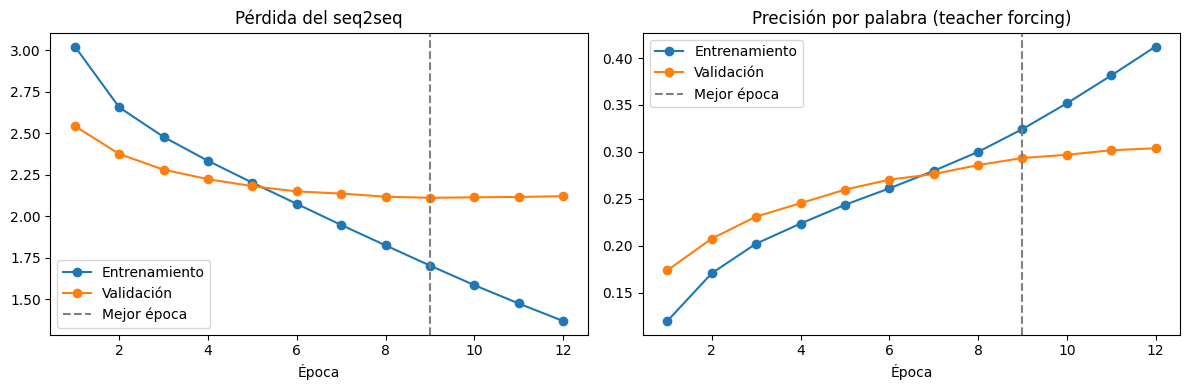

In [59]:
metricas_tr = pd.DataFrame(historial_tr.history)
metricas_tr.index = range(1, len(metricas_tr) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(metricas_tr.index, metricas_tr["loss"], marker="o", label="Entrenamiento")
ejes[0].plot(metricas_tr.index, metricas_tr["val_loss"], marker="o", label="Validación")
ejes[0].axvline(mejor_epoca_tr, color="gray", linestyle="--", label="Mejor época")
ejes[0].set_title("Pérdida del seq2seq")
ejes[0].set_xlabel("Época")
ejes[0].legend()
ejes[1].plot(metricas_tr.index, metricas_tr["accuracy"], marker="o", label="Entrenamiento")
ejes[1].plot(metricas_tr.index, metricas_tr["val_accuracy"], marker="o", label="Validación")
ejes[1].axvline(mejor_epoca_tr, color="gray", linestyle="--", label="Mejor época")
ejes[1].set_title("Precisión por palabra (teacher forcing)")
ejes[1].set_xlabel("Época")
ejes[1].legend()
plt.tight_layout()
plt.show()

In [60]:
vocabulario_en = tokenizador_en.get_vocabulary()
id_start = vocabulario_en.index("[start]")
id_end = vocabulario_en.index("[end]")

In [61]:
def traducir_lote(frases_es):
    tokens_es = keras.ops.convert_to_numpy(tokenizador_es(frases_es))
    n = len(frases_es)
    tokens_destino = np.zeros((n, longitud_destino), dtype="int32")
    tokens_destino[:, 0] = id_start
    terminadas = np.zeros(n, dtype=bool)
    for i in range(longitud_destino - 1):
        predicciones = seq2seq(
            [keras.ops.convert_to_tensor(tokens_es), keras.ops.convert_to_tensor(tokens_destino)],
            training=False,
        )
        probabilidades = keras.ops.convert_to_numpy(predicciones[:, i, :]).copy()
        probabilidades[:, [0, 1, id_start]] = 0  # prohibir relleno, [UNK] y [start]
        siguientes = probabilidades.argmax(axis=-1)
        siguientes[terminadas] = 0
        tokens_destino[:, i + 1] = siguientes
        terminadas |= siguientes == id_end
        if terminadas.all():
            break
    traducciones = []
    for fila in tokens_destino:
        palabras = []
        for token_id in fila[1:]:
            if token_id in (0, id_end):
                break
            palabras.append(vocabulario_en[token_id])
        traducciones.append(" ".join(palabras))
    return traducciones

In [62]:
def traducir(frases_es, tamano=256):
    resultado = []
    for i in range(0, len(frases_es), tamano):
        resultado.extend(traducir_lote(frases_es[i : i + tamano]))
    return resultado

In [63]:
ejemplos = pares_prueba[:10]
traducciones_ejemplo = traducir([es for es, en in ejemplos])
for (espanol, referencia), traduccion in zip(ejemplos, traducciones_ejemplo):
    referencia = referencia.replace("[start] ", "").replace(" [end]", "")
    print(f"ES:         {espanol}")
    print(f"Referencia: {referencia}")
    print(f"Modelo:     {traduccion}\n")

ES:         Esta cuenta está empezando a quedar polvo otra vez.
Referencia: This account is starting to get dusty again
Modelo:     this is a lot of restlessness in my car

ES:         Reí a carcajadas, feliz. 5 minutos Después el ánimo cambia otra vez, qué raro
Referencia: I laughed out loud, happy. 5 minutes Then the mood changes again, weird
Modelo:     anyone know how much people are the best painless painless way to be over

ES:         mañana shbt
Referencia: morning shbt
Modelo:     crazy depression

ES:         no pinta muy bonita afuera hoy.
Referencia: it doesn't look very nice outside today.
Modelo:     no one of a sudden he was delicious

ES:         Mmm, las habilidades culinarias de mi madre están mejorando. Huele muy bien! ¡Me encanta la comida casera!
Referencia: Mmm mummy's culinary skills has been improving. Smells so good! i'm loving home cooked food!
Modelo:     mizzzidc you re a lot of making a lot of cb and then i miss my eye

ES:         por favor, no pierdas nad

- **Curvas:** la pérdida de entrenamiento y la de validación se cruzan en la **época 6** (en precisión, en la 7). Después, el entrenamiento sigue mejorando de forma casi lineal y la validación se aplana por completo. Es el patrón clásico de sobreajuste, más pronunciado que en el Punto 1 por la combinación de pocos datos y muchos parámetros.
- **Calidad de las traducciones:** el modelo genera **inglés fluido pero casi siempre desconectado del significado de la entrada**. Frases como "*i had a good day for a long time*" o "*i have to be patient*" son gramaticales, pero no traducen la frase en español. El decodificador se comporta como un **modelo de lenguaje del inglés de redes sociales** que usa muy poco la información del codificador. Es la consecuencia práctica del cuello de botella de un único vector de 512 dimensiones, entrenado con solo ~10 000 ejemplos.
- **Lo que sí aprendió:**
  - **Palabras iniciales y marcadores de alta frecuencia:** "*mañana*" → "*morning*", "*por favor*" → "*please*", "*no...*" → "*no...*".
  - **El tipo de oración:** "*¿A alguien más...?*" → "*does anyone...*". Reconoce que es una pregunta dirigida a otros y elige la estructura inglesa correcta para empezarla.
  - El estilo informal en minúsculas y sin apóstrofes (*dont*, *havent*, *i m*), consecuencia de la estandarización del tokenizador.
- **Patrón general:** la primera o las dos primeras palabras suelen tener relación con la entrada y luego la traducción "se desvía". Es el **sesgo de exposición** en acción: tras el primer error, el decodificador condiciona sus siguientes predicciones en su propia salida equivocada y se aleja cada vez más de la referencia.
- **Sesgo del dominio:** en la frase sobre soledad, el modelo generó "*i am going to kill myself*", que **no está en la entrada**. Las expresiones de ideación suicida son muy frecuentes en el dataset, y el decodificador las produce ante contextos emocionales negativos. En un sistema real esto sería un problema serio: un traductor que **agrega contenido sensible** que el autor no escribió. Ilustra cómo el sesgo de los datos de entrenamiento se filtra en las salidas.
- **Nombres propios y palabras raras:** *aprilmcvey*, *kristensaywhaa* o *shbt* se pierden por completo. Están fuera del vocabulario (`[UNK]`), y como se prohibió generar `[UNK]`, el modelo los omite o los reemplaza. Una tokenización por subpalabras (BPE o WordPiece) permitiría copiarlos.

## Evaluación con BLEU, ROUGE y F1

Se traducen las 2 112 frases de prueba y se comparan con sus referencias. Antes de comparar, las referencias se normalizan igual que la salida del modelo: minúsculas y sin puntuación. Si no se hiciera, el modelo quedaría penalizado por diferencias de formato que nunca pudo aprender.

| Métrica | Qué mide | Cómo se calcula |
|---|---|---|
| **BLEU** | Precisión de n-gramas (1 a 4) de la traducción frente a la referencia, con penalización por brevedad | `sacrebleu.corpus_bleu` sobre todo el conjunto de prueba (escala 0 a 100) |
| **ROUGE-1 / ROUGE-2** | Coincidencia de unigramas y bigramas, con énfasis en la cobertura (*recall*) | `rouge_score`, promedio por frase de precisión, *recall* y F |
| **ROUGE-L** | Subsecuencia común más larga: premia conservar el **orden** de las palabras | `rouge_score`, promedio por frase |
| **F1 por tokens** | Media armónica entre precisión y *recall* de las palabras compartidas, sin importar el orden | Implementación propia, estilo SQuAD, promedio por frase |


In [64]:
!pip install -q sacrebleu rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [65]:
import collections
import sacrebleu
from rouge_score import rouge_scorer

In [66]:
patron_puntuacion = f"[{re.escape(caracteres_a_quitar)}]"

def normalizar_texto(texto):
    texto = texto.replace("[start]", "").replace("[end]", "").lower()
    texto = re.sub(patron_puntuacion, "", texto)
    return " ".join(texto.split())

def f1_tokens(prediccion, referencia):
    tokens_pred = prediccion.split()
    tokens_ref = referencia.split()
    comunes = sum((collections.Counter(tokens_pred) & collections.Counter(tokens_ref)).values())
    if comunes == 0:
        return 0.0, 0.0, 0.0
    precision = comunes / len(tokens_pred)
    recall = comunes / len(tokens_ref)
    return precision, recall, 2 * precision * recall / (precision + recall)

In [67]:
evaluador_rouge = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)

In [68]:
def evaluar(predicciones, referencias):
    bleu = sacrebleu.corpus_bleu(predicciones, [referencias])
    rouge = {clave: [] for clave in ["rouge1", "rouge2", "rougeL"]}
    f1 = []
    for prediccion, referencia in zip(predicciones, referencias):
        puntajes = evaluador_rouge.score(referencia, prediccion)
        for clave in rouge:
            rouge[clave].append(puntajes[clave])
        f1.append(f1_tokens(prediccion, referencia))
    f1 = np.array(f1)
    return {
        "BLEU": bleu.score,
        "BLEU-1 (prec. unigramas)": bleu.precisions[0],
        "BLEU-2 (prec. bigramas)": bleu.precisions[1],
        "BLEU-3 (prec. trigramas)": bleu.precisions[2],
        "BLEU-4 (prec. 4-gramas)": bleu.precisions[3],
        "Penalización por brevedad": bleu.bp,
        "ROUGE-1 F": 100 * np.mean([p.fmeasure for p in rouge["rouge1"]]),
        "ROUGE-1 recall": 100 * np.mean([p.recall for p in rouge["rouge1"]]),
        "ROUGE-2 F": 100 * np.mean([p.fmeasure for p in rouge["rouge2"]]),
        "ROUGE-L F": 100 * np.mean([p.fmeasure for p in rouge["rougeL"]]),
        "F1 tokens": 100 * f1[:, 2].mean(),
        "Precisión tokens": 100 * f1[:, 0].mean(),
        "Recall tokens": 100 * f1[:, 1].mean(),
    }

In [69]:
frases_es_prueba = [es for es, en in pares_prueba]
referencias_prueba = [normalizar_texto(en) for es, en in pares_prueba]

In [70]:
inicio_eval = time.time()
traducciones_prueba = traducir(frases_es_prueba)
print(f"Frases traducidas: {len(traducciones_prueba)} en {time.time() - inicio_eval:.1f} s")

Frases traducidas: 2112 en 19.6 s


In [71]:
predicciones_prueba = [normalizar_texto(t) for t in traducciones_prueba]
copias_prueba = [normalizar_texto(es) for es in frases_es_prueba]

tabla_metricas = pd.DataFrame({
    "seq2seq GRU": evaluar(predicciones_prueba, referencias_prueba),
    "Línea base (copiar español)": evaluar(copias_prueba, referencias_prueba),
}).round(2)
print()
print(tabla_metricas.to_string())


                           seq2seq GRU  Línea base (copiar español)
BLEU                              2.62                         2.06
BLEU-1 (prec. unigramas)         16.57                         9.43
BLEU-2 (prec. bigramas)           4.00                         2.59
BLEU-3 (prec. trigramas)          1.40                         1.19
BLEU-4 (prec. 4-gramas)           0.51                         0.68
Penalización por brevedad         1.00                         0.98
ROUGE-1 F                        17.77                         9.41
ROUGE-1 recall                   18.35                         9.80
ROUGE-2 F                         4.91                         2.40
ROUGE-L F                        17.08                         9.31
F1 tokens                        17.77                         9.49
Precisión tokens                 17.83                         9.56
Recall tokens                    18.35                         9.61


In [72]:
largo_pred = np.mean([len(p.split()) for p in predicciones_prueba])
largo_ref = np.mean([len(r.split()) for r in referencias_prueba])
print(f"Longitud media: modelo {largo_pred:.1f} palabras, referencia {largo_ref:.1f} palabras")

Longitud media: modelo 9.9 palabras, referencia 9.2 palabras


- **La traducción por lotes funcionó:** las 2 112 frases de prueba se tradujeron en **19.6 segundos**. Con el método frase por frase del ejemplo habría tomado más de 20 minutos.
- **BLEU = 2.62, un valor muy bajo.** Un traductor útil suele estar por encima de 20 a 30. Además, apenas supera a la **línea base de copiar el español sin traducir (2.06)**.
- **El desglose de BLEU muestra dónde falla:**
  - **Unigramas (BLEU-1 = 16.6 %):** 1 de cada 6 palabras generadas aparece en la referencia, casi el doble que la línea base (9.4 %). El modelo **sí elige algunas palabras correctas**.
  - **De bigramas a 4-gramas (4.0 % → 1.4 % → 0.5 %):** la precisión se desploma. El modelo casi nunca acierta **secuencias** de palabras.
- **ROUGE confirma el diagnóstico:**
  - **ROUGE-1 F = 17.8**, el doble que la línea base: el modelo recupera ~18 % de las palabras de la referencia.
  - **ROUGE-2 F = 4.9**: los pares de palabras consecutivas casi no coinciden.
  - **ROUGE-L (17.1) es casi igual a ROUGE-1 (17.8).** La subsecuencia común más larga apenas supera la coincidencia de palabras sueltas, así que las palabras acertadas están **aisladas** y no forman fragmentos traducidos en orden.
- **F1 por tokens = 17.8, con precisión (17.8) y *recall* (18.4) equilibrados.** El modelo simplemente acierta ~1 de cada 6 palabras.
- **Por qué los resultados son bajos:**
  1. **Pocos datos:** ~10 000 pares de entrenamiento, ~8 veces menos que el ejemplo del libro.
  2. **Referencias parafraseadas y ruidosas:** frases de redes sociales con jerga, errores, nombres de usuario y traducciones no literales.
  3. **Cuello de botella del codificador:** toda la frase se comprime en un único vector de 512 dimensiones.
  4. **Vocabulario cerrado de palabras:** los nombres propios y la jerga, muy frecuentes en este dominio, se pierden como `[UNK]`.

## Conclusiones generales

- **Las RNN aprenden muy bien la forma del lenguaje y con dificultad su significado.** El modelo de caracteres del Punto 1 aprendió ortografía, puntuación y el estilo de Cervantes sin ninguna regla explícita. El seq2seq del Punto 2 aprendió a producir inglés. En ambos casos falló la coherencia semántica: en la generación, el texto no tiene un hilo de sentido; en la traducción, el significado de la frase de entrada no llega a la salida.

- **La cantidad y la calidad de los datos determinan el resultado más que la arquitectura.** En el Punto 1, tres variantes de arquitectura convergieron a la misma pérdida (~1.24), lo que apunta a un límite impuesto por el corpus. En el Punto 2, ~10 000 pares ruidosos y parafraseados limitaron el BLEU a 2.6, por debajo de lo que la arquitectura podría lograr con más datos.

- **La decodificación es parte del modelo.** La misma red produjo texto repetitivo o variado según la temperatura (Punto 1), y el sesgo de exposición de la decodificación voraz explica buena parte de la deriva de las traducciones (Punto 2).

- **Los modelos reproducen los sesgos de sus datos.** El generador de texto adoptó el vocabulario del siglo XVII, y el traductor introdujo expresiones de ideación suicida que no estaban en la entrada, porque eran frecuentes en el dataset.

- **El cuello de botella del seq2seq con RNN** (comprimir toda la frase en un vector) motiva directamente el paso a los **mecanismos de atención y los Transformers**.